# 6BUIS017W – Market Analysis and Stock Segmentation Using RFM

**Student ID: W2118173**

**GitHub repository: https://github.com/7omain/Uni-Coursework**

**Data retrieved:** 2026-10-21

## 0. Setup and environment

In [1]:
!pip install -q yfinance==0.2.66

import os, sys, datetime as dt, requests
from io import StringIO
import pandas as pd
import yfinance as yf

RETRIEVAL_DATE = "2026-10-21"
START, END = "2021-01-01", "2025-01-01"
os.makedirs("data", exist_ok=True)


SNAPSHOT_URL  = "https://raw.githubusercontent.com/7omain/Uni-Coursework/refs/heads/main/Data/prices_raw_2021-01-01_2025-01-01_retrieved_2026-10-21.csv.gz"
SNAPSHOT_FILE = f"data/prices_raw_{START}_{END}_retrieved_{RETRIEVAL_DATE}.csv.gz"

versions = {"python": sys.version.split()[0], "pandas": pd.__version__,
            "yfinance": yf.__version__, "retrieval_date": RETRIEVAL_DATE}
pd.Series(versions).to_csv("data/versions.csv")
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'yfinance': '0.2.66', 'retrieval_date': '2026-10-21'}


# Task 1 – Data Preparation and Feature Engineering

## 1.1 Ticker selection and data acquisition

### 1.1.1 S&P 500 constituent list

In [2]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
CONSTITUENTS_URL = "https://raw.githubusercontent.com/7omain/Uni-Coursework/refs/heads/main/Data/sp500_constituents_2026-10-21.csv"
try:
    sp500 = pd.read_csv(CONSTITUENTS_URL)
    print("Loaded preserved constituent list from GitHub")
except Exception:
    resp = requests.get(url, headers={"User-Agent": "Mozilla/5.0 (uni coursework)"})
    resp.raise_for_status()
    sp500 = pd.read_html(StringIO(resp.text))[0]
sp500["yahoo_ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)
sp500.to_csv(f"data/sp500_constituents_{RETRIEVAL_DATE}.csv", index=False)

print(len(sp500), "constituents retrieved on", RETRIEVAL_DATE)
sp500[["Symbol", "yahoo_ticker", "Security", "GICS Sector"]].head()

Loaded preserved constituent list from GitHub
503 constituents retrieved on 2026-10-21


,Symbol,yahoo_ticker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology


### 1.1.2 Share symbol conversion check

In [3]:
sp500[sp500["Symbol"].str.contains(".", regex=False)][["Symbol", "yahoo_ticker"]]

,Symbol,yahoo_ticker
60,BRK.B,BRK-B
76,BF.B,BF-B


### 1.1.3 Price and benchmark download

In [4]:
DOWNLOAD_FRESH = not (SNAPSHOT_URL or os.path.exists(SNAPSHOT_FILE))

if DOWNLOAD_FRESH:
    tickers = sp500["yahoo_ticker"].tolist() + ["^GSPC"]
    raw = yf.download(tickers, start=START, end=END,
                      auto_adjust=False,
                      actions=True,
                      group_by="column", threads=True, progress=True)
    print(raw.shape)
    print(raw.columns.get_level_values(0).unique().tolist())
else:
    print("Preserved snapshot available - fresh download skipped.")

Preserved snapshot available - fresh download skipped.


### 1.1.4 Failed downloads investigation

In [5]:
failed = ["HONA", "VYLR", "FDXF", "SNDK", "Q"]
sp500[sp500["yahoo_ticker"].isin(failed)][["Symbol", "Security", "GICS Sector", "Date added"]]

,Symbol,Security,GICS Sector,Date added
192,FDXF,FedEx Freight,Industrials,2026-06-01
233,HONA,Honeywell Aerospace,Industrials,2026-06-29
379,Q,Qnity Electronics,Information Technology,2025-11-03
402,SNDK,Sandisk,Information Technology,2025-11-28
478,VYLR,Vylor,Consumer Staples,2026-10-01


### 1.1.5 Saving and reloading the raw data snapshot

In [6]:
if DOWNLOAD_FRESH:
    long = (raw.stack(level=1, future_stack=True)
               .rename_axis(["Date", "Ticker"])
               .reset_index())
    long.to_csv(SNAPSHOT_FILE, index=False)
    print("Snapshot saved:", SNAPSHOT_FILE, "|", round(os.path.getsize(SNAPSHOT_FILE) / 1e6, 1), "MB")

In [7]:
check = pd.read_csv(SNAPSHOT_URL or SNAPSHOT_FILE, parse_dates=["Date"])
print("Loaded from:", SNAPSHOT_URL or SNAPSHOT_FILE)
print(check.shape, "|", check["Ticker"].nunique(), "tickers |",
      check["Date"].min().date(), "to", check["Date"].max().date())
check.head()

Loaded from: https://raw.githubusercontent.com/7omain/Uni-Coursework/refs/heads/main/Data/prices_raw_2021-01-01_2025-01-01_retrieved_2026-10-21.csv.gz
(506520, 10) | 504 tickers | 2021-01-04 to 2024-12-31


,Date,Ticker,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
0,2021-01-04,A,114.009109,118.639999,0.194,120.089996,117.110001,118.940002,0.0,2030700.0
1,2021-01-04,AAPL,125.632492,129.410004,0.000,133.610001,126.760002,133.520004,0.0,143301900.0
2,2021-01-04,ABBV,84.219124,105.410004,0.000,107.349998,103.860001,107.180000,0.0,9523400.0
3,2021-01-04,ABNB,139.149994,139.149994,0.000,151.005005,137.000000,150.990005,0.0,6409900.0
4,2021-01-04,ABT,97.269699,109.110001,0.000,110.250000,107.260002,109.529999,0.0,6192000.0


### 1.1.6 Coverage check and exclusion log

In [8]:
adj = check.pivot(index="Date", columns="Ticker", values="Adj Close")
bench_days = adj["^GSPC"].dropna().index

coverage = pd.DataFrame({
    "first_date": adj.apply(lambda s: s.first_valid_index()),
    "last_date":  adj.apply(lambda s: s.last_valid_index()),
    "n_days":     adj.notna().sum(),
})
coverage["expected_days"] = len(bench_days)

def reason(row):
    if row.n_days == 0:                 return "no data returned"
    if row.first_date > bench_days[0]:  return f"listed later ({row.first_date.date()})"
    if row.last_date  < bench_days[-1]: return f"history ends early ({row.last_date.date()})"
    if row.n_days < len(bench_days):    return "missing trading days"
    return None

coverage["exclusion_reason"] = coverage.apply(reason, axis=1)

exclusions = (coverage[coverage.exclusion_reason.notna()]
              .drop(index="^GSPC", errors="ignore")
              .merge(sp500.set_index("yahoo_ticker")[["Security", "GICS Sector", "Date added"]],
                     left_index=True, right_index=True, how="left")
              .sort_values("first_date"))
exclusions.to_csv("data/exclusion_log_1_1.csv")

retained = coverage[coverage.exclusion_reason.isna()].drop(index="^GSPC", errors="ignore").index
print("Retained:", len(retained), "| Excluded:", len(exclusions))
exclusions

Retained: 487 | Excluded: 16


,first_date,last_date,n_days,expected_days,exclusion_reason,Security,GICS Sector,Date added
Ticker,,,,,,,,
EXE,2021-02-10,2024-12-31,979,1005,listed later (2021-02-10),Expand Energy,Energy,2025-03-24
COIN,2021-04-14,2024-12-31,936,1005,listed later (2021-04-14),Coinbase,Financials,2025-05-19
APP,2021-04-15,2024-12-31,935,1005,listed later (2021-04-15),AppLovin,Communication Services,2025-09-22
HOOD,2021-07-29,2024-12-31,862,1005,listed later (2021-07-29),Robinhood Markets,Financials,2025-09-22
CEG,2022-01-19,2024-12-31,742,1005,listed later (2022-01-19),Constellation Energy,Utilities,2022-02-02
GEHC,2022-12-15,2024-12-31,513,1005,listed later (2022-12-15),GE HealthCare,Health Care,2023-01-04
VLTO,2023-10-04,2024-12-31,313,1005,listed later (2023-10-04),Veralto,Industrials,2023-10-02
RDDT,2024-03-21,2024-12-31,197,1005,listed later (2024-03-21),Reddit,Communication Services,2026-08-18
SOLV,2024-03-26,2024-12-31,194,1005,listed later (2024-03-26),Solventum,Health Care,2024-04-01


In [9]:
added = pd.to_datetime(sp500.set_index("yahoo_ticker").loc[retained, "Date added"], errors="coerce")
late = added[added > "2021-01-01"]
print(f"{len(late)} of {len(retained)} retained shares joined the S&P 500 after 1 Jan 2021")
late.sort_values().tail(10)

73 of 487 retained shares joined the S&P 500 after 1 Jan 2021


,Date added
Ticker,
COHR,2026-03-23
CASY,2026-04-09
VEEV,2026-05-07
MRVL,2026-06-22
FLEX,2026-06-22
FERG,2026-08-05
P,2026-09-21
BE,2026-09-21
ILMN,2026-09-21


## 1.2 Data validation and alignment

In [10]:
data = check[check["Ticker"].isin(list(retained) + ["^GSPC"])].copy()
shares = data[data["Ticker"] != "^GSPC"]
print(data["Ticker"].nunique(), "tickers (shares + benchmark),", len(data), "rows")

488 tickers (shares + benchmark), 490440 rows


### 1.2.1 Duplicate dates

In [11]:
dups = data.duplicated(subset=["Date", "Ticker"]).sum()
print("Duplicate Date–Ticker rows:", dups)

Duplicate Date–Ticker rows: 0


### 1.2.2 Missing values

In [12]:
fields = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
print("Missing values per column (retained shares):")
print(shares[fields].isna().sum())

days = shares.groupby("Ticker")["Adj Close"].count()
print("\nTrading days per share – min:", days.min(), "| max:", days.max())

Missing values per column (retained shares):
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

Trading days per share – min: 1005 | max: 1005


### 1.2.3 Non-positive prices and volume errors

In [13]:
validation = pd.Series({
    "Non-positive Close":       (shares["Close"] <= 0).sum(),
    "Non-positive Adj Close":   (shares["Adj Close"] <= 0).sum(),
    "High below Low":           (shares["High"] < shares["Low"]).sum(),
    "Close outside High–Low":   ((shares["Close"] > shares["High"] * 1.0001) |
                                 (shares["Close"] < shares["Low"] * 0.9999)).sum(),
    "Negative Volume":          (shares["Volume"] < 0).sum(),
    "Zero Volume":              (shares["Volume"] == 0).sum(),
    "Non-whole-number Volume":  (shares["Volume"] % 1 != 0).sum(),
}, name="rows failing")
validation.to_csv("data/validation_checks_1_2.csv")
validation

,rows failing
Non-positive Close,0
Non-positive Adj Close,0
High below Low,0
Close outside High–Low,0
Negative Volume,0
Zero Volume,451
Non-whole-number Volume,0


In [14]:
zero = shares[shares["Volume"] == 0]
print("Zero-volume rows:", len(zero), "| shares affected:", zero["Ticker"].nunique(),
      "| distinct dates:", zero["Date"].nunique())

print("\nShares with the most zero-volume days:")
print(zero["Ticker"].value_counts().head(10))

print("\nShare of zero-volume days where High ≠ Low:", round((zero["High"] != zero["Low"]).mean(), 3))

Zero-volume rows: 451 | shares affected: 2 | distinct dates: 435

Shares with the most zero-volume days:
Ticker
SW      424
FERG     27
Name: count, dtype: int64

Share of zero-volume days where High ≠ Low: 0.0


In [15]:
zero_counts = zero["Ticker"].value_counts()
volume_exclusions = pd.DataFrame({
    "zero_volume_days": zero_counts,
    "exclusion_reason": [f"{n} zero-volume days with flat prices (High = Low): "
                         "placeholder data, no genuine US trading" for n in zero_counts],
})
volume_exclusions = volume_exclusions.merge(
    sp500.set_index("yahoo_ticker")[["Security", "GICS Sector", "Date added"]],
    left_index=True, right_index=True, how="left")
volume_exclusions.to_csv("data/exclusion_log_1_2.csv")

retained = retained.drop(volume_exclusions.index)
data   = check[check["Ticker"].isin(list(retained) + ["^GSPC"])].copy()
shares = data[data["Ticker"] != "^GSPC"]
print("Retained shares now:", len(retained))
volume_exclusions

Retained shares now: 485


,zero_volume_days,exclusion_reason,Security,GICS Sector,Date added
Ticker,,,,,
SW,424,424 zero-volume days with flat prices (High = ...,Smurfit Westrock,Materials,2024-07-08
FERG,27,27 zero-volume days with flat prices (High = L...,Ferguson Enterprises,Industrials,2026-08-05


In [16]:
recheck = pd.Series({
    "Zero Volume":                  (shares["Volume"] == 0).sum(),
    "Flat-price days (High = Low)": (shares["High"] == shares["Low"]).sum(),
    "Non-positive Close":           (shares["Close"] <= 0).sum(),
    "Negative Volume":              (shares["Volume"] < 0).sum(),
}, name="rows failing after exclusions")
recheck.to_csv("data/validation_checks_1_2_after_exclusions.csv")
print(recheck, "\n")

shares[shares["High"] == shares["Low"]][["Date", "Ticker", "Open", "High", "Low", "Close", "Volume"]]

Zero Volume                     0
Flat-price days (High = Low)    1
Non-positive Close              0
Negative Volume                 0
Name: rows failing after exclusions, dtype: int64 



,Date,Ticker,Open,High,Low,Close,Volume
308508,2023-06-09,BIIB,308.880005,308.880005,308.880005,308.880005,8100.0


### 1.2.4 Corporate actions (splits and dividends)

In [17]:
splits = shares.loc[shares["Stock Splits"] > 0, ["Date", "Ticker", "Stock Splits"]].copy()
div_payers = shares.loc[shares["Dividends"] > 0, "Ticker"].nunique()
print(len(splits), "stock splits across", splits["Ticker"].nunique(), "shares")
print(div_payers, "of", shares["Ticker"].nunique(), "shares paid dividends")

close_w = shares.pivot(index="Date", columns="Ticker", values="Close")
adj_w   = shares.pivot(index="Date", columns="Ticker", values="Adj Close")
r_close = close_w.pct_change(fill_method=None)
r_adj   = adj_w.pct_change(fill_method=None)

splits["Close return on split day"]     = [r_close.at[d, t] for d, t in zip(splits["Date"], splits["Ticker"])]
splits["Adj Close return on split day"] = [r_adj.at[d, t]   for d, t in zip(splits["Date"], splits["Ticker"])]
print("Largest absolute Close return on any split day:",
      round(splits["Close return on split day"].abs().max(), 4))
splits.round(4)

61 stock splits across 53 shares
392 of 485 shares paid dividends
Largest absolute Close return on any split day: 0.0766


,Date,Ticker,Stock Splits,Close return on split day,Adj Close return on split day
21205,2021-03-05,APH,2.000,0.0253,0.0253
31146,2021-04-01,SHW,3.000,0.0152,0.0152
52729,2021-06-03,MRK,1.048,0.0209,0.0209
61101,2021-06-28,CSGP,10.000,-0.0379,-0.0379
61606,2021-06-29,CSX,3.000,-0.0067,-0.0067
...,...,...,...,...,...
475558,2024-10-03,LRCX,10.000,-0.0037,-0.0037
496976,2024-12-04,ANET,4.000,0.0175,0.0175
500639,2024-12-13,ETR,2.000,0.0014,0.0014
501330,2024-12-16,PANW,2.000,0.0302,0.0302


In [18]:
extreme = r_adj.stack().rename("daily return").reset_index()
extreme = extreme[extreme["daily return"].abs() > 0.25].sort_values("daily return")
print(len(extreme), "daily moves larger than ±25%")
extreme

60 daily moves larger than ±25%


,Date,Ticker,daily return
398382,2024-04-11,GL,-0.531402
235343,2022-12-07,CVNA,-0.429210
433735,2024-07-26,DXCM,-0.406583
224673,2022-11-04,CVNA,-0.389547
139165,2022-02-23,VRT,-0.367399
157943,2022-04-20,NFLX,-0.351166
224988,2022-11-04,TWLO,-0.346083
466478,2024-10-30,SMCI,-0.326751
445359,2024-08-29,DG,-0.321463
433271,2024-07-25,EW,-0.313398


In [19]:
g = data[data["Ticker"] == "^GSPC"]
print("^GSPC Close equals Adj Close on every day:",
      bool(((g["Close"] - g["Adj Close"]).abs() < 1e-6).all()))

^GSPC Close equals Adj Close on every day: True


### 1.2.5 Weekly resampling and benchmark alignment

In [20]:
adj_wide = data.pivot(index="Date", columns="Ticker", values="Adj Close")

weekly_px = adj_wide.resample("W-FRI").last()

monday = weekly_px.index - pd.Timedelta(days=4)
last_study_day = pd.Timestamp(END) - pd.Timedelta(days=1)
complete = (monday >= pd.Timestamp(START)) & (weekly_px.index <= last_study_day)
print("Incomplete weeks dropped:", [str(d.date()) for d in weekly_px.index[~complete]])
weekly_px = weekly_px[complete]

days_in_week = adj_wide["^GSPC"].resample("W-FRI").count()[complete]
print("\nTrading days per week (count of weeks):")
print(days_in_week.value_counts().sort_index())

Incomplete weeks dropped: ['2025-01-03']

Trading days per week (count of weeks):
^GSPC
4     37
5    171
Name: count, dtype: int64


In [21]:
weekly_ret = weekly_px.pct_change(fill_method=None).iloc[1:]

bench_ret = weekly_ret["^GSPC"]
share_ret = weekly_ret.drop(columns="^GSPC")

assert share_ret.index.equals(bench_ret.index)
print("Aligned weekly observations:", len(bench_ret),
      "| from", bench_ret.index[0].date(), "to", bench_ret.index[-1].date())
print("Shares:", share_ret.shape[1], "| missing weekly returns:", int(share_ret.isna().sum().sum()))

weekly_ret.to_csv("data/weekly_returns.csv")

Aligned weekly observations: 207 | from 2021-01-15 to 2024-12-27
Shares: 485 | missing weekly returns: 0


## 1.3 Weekly return and weekly beta

### 1.3.1 Mean weekly return

In [22]:
import numpy as np

n_weeks = share_ret.count()
mean_ret = share_ret.mean()

n = len(bench_ret)
geo_ret = (weekly_px[share_ret.columns].iloc[-1] / weekly_px[share_ret.columns].iloc[0]) ** (1 / n) - 1

print("Weekly observations per share – min:", n_weeks.min(), "| max:", n_weeks.max())
print("S&P 500 mean weekly return:", round(bench_ret.mean(), 5))
print("\nMean weekly return across shares:")
print(mean_ret.describe().round(5))
print("\nAverage gap arithmetic – geometric:", round((mean_ret - geo_ret).mean(), 5))

Weekly observations per share – min: 207 | max: 207
S&P 500 mean weekly return: 0.0024

Mean weekly return across shares:
count    485.00000
mean       0.00287
std        0.00264
min       -0.00447
25%        0.00118
50%        0.00262
75%        0.00421
max        0.01777
dtype: float64

Average gap arithmetic – geometric: 0.00098


In [23]:
t = "AAPL"
p = weekly_px[t]

manual_first = p.iloc[1] / p.iloc[0] - 1
manual_mean = sum(share_ret[t]) / len(share_ret[t])

print(f"{t} first weekly return – by hand: {manual_first:.6f} | from code: {share_ret[t].iloc[0]:.6f}")
print(f"{t} mean weekly return  – by hand: {manual_mean:.6f} | from code: {mean_ret[t]:.6f}")
print(f"{t} weeks used: {len(share_ret[t])}, from {share_ret.index[0].date()} to {share_ret.index[-1].date()}")

AAPL first weekly return – by hand: -0.037183 | from code: -0.037183
AAPL mean weekly return  – by hand: 0.003930 | from code: 0.003930
AAPL weeks used: 207, from 2021-01-15 to 2024-12-27


### 1.3.2 Weekly beta

In [24]:
bench_var = bench_ret.var()
beta = share_ret.apply(lambda s: s.cov(bench_ret)) / bench_var

print("Benchmark beta with itself:", round(bench_ret.cov(bench_ret) / bench_var, 6))
print("Aligned weekly observations used for every beta:", n)

slope = share_ret.apply(lambda s: np.polyfit(bench_ret, s, 1)[0])
print("Largest difference between beta and regression slope:", f"{(beta - slope).abs().max():.2e}")

r2 = share_ret.corrwith(bench_ret) ** 2
beta_se = np.sqrt((1 - r2) / (n - 2)) * share_ret.std() / bench_ret.std()

print("\nBeta across shares:")
print(beta.describe().round(3))
print("\nMedian R²:", round(r2.median(), 3), "| median standard error of beta:", round(beta_se.median(), 3))

Benchmark beta with itself: 1.0
Aligned weekly observations used for every beta: 207
Largest difference between beta and regression slope: 2.89e-15

Beta across shares:
count    485.000
mean       0.972
std        0.406
min        0.055
25%        0.667
50%        0.948
75%        1.179
max        3.779
dtype: float64

Median R²: 0.284 | median standard error of beta: 0.101


### 1.3.3 Risk-return feature table

In [25]:
sector = sp500.set_index("yahoo_ticker")["GICS Sector"]

features_rr = pd.DataFrame({
    "sector":                  sector.reindex(share_ret.columns),
    "n_weeks":                 n_weeks,
    "mean_weekly_return":      mean_ret,
    "geometric_weekly_return": geo_ret,
    "beta":                    beta,
    "beta_se":                 beta_se,
    "r_squared":               r2,
})
features_rr.index.name = "Ticker"
features_rr.to_csv("data/features_risk_return.csv")

print(features_rr.shape)
features_rr.describe().round(4)

(485, 7)


,n_weeks,mean_weekly_return,geometric_weekly_return,beta,beta_se,r_squared
count,485.0,485.0000,485.0000,485.0000,485.0000,485.0000
mean,207.0,0.0029,0.0019,0.9720,0.1121,0.2799
std,0.0,0.0026,0.0025,0.4059,0.0412,0.1313
min,207.0,-0.0045,-0.0060,0.0555,0.0568,0.0022
25%,207.0,0.0012,0.0004,0.6666,0.0860,0.1715
50%,207.0,0.0026,0.0018,0.9480,0.1006,0.2839
75%,207.0,0.0042,0.0033,1.1792,0.1271,0.3799
max,207.0,0.0178,0.0114,3.7786,0.4362,0.6387


In [26]:
cols = ["sector", "mean_weekly_return", "beta", "r_squared"]
print("Highest beta:");  display(features_rr.nlargest(5, "beta")[cols].round(4))
print("Lowest beta:");   display(features_rr.nsmallest(5, "beta")[cols].round(4))
print("Median beta by sector:")
features_rr.groupby("sector")["beta"].median().sort_values().round(3)

Highest beta:


,sector,mean_weekly_return,beta,r_squared
Ticker,,,,
CVNA,Consumer Discretionary,0.0110,3.7786,0.2679
XYZ,Financials,-0.0016,2.5045,0.4619
COHR,Information Technology,0.0039,2.1393,0.3526
NVDA,Information Technology,0.0136,2.1260,0.4781
TWLO,Information Technology,-0.0022,2.0734,0.3084


Lowest beta:


,sector,mean_weekly_return,beta,r_squared
Ticker,,,,
GIS,Consumer Staples,0.0015,0.0555,0.0022
SJM,Consumer Staples,0.0008,0.1756,0.0177
MRK,Health Care,0.0021,0.1983,0.0221
BMY,Health Care,0.0008,0.2250,0.0248
KHC,Consumer Staples,0.0009,0.2272,0.0277


Median beta by sector:


,beta
sector,
Consumer Staples,0.469
Utilities,0.511
Energy,0.750
Health Care,0.759
Real Estate,0.881
Communication Services,0.887
Materials,0.935
Industrials,0.999
Financials,1.008


## 1.4 Adapted RFM calculations

### 1.4.0 Observation date and high-volume event flag

In [27]:
vol   = shares.pivot(index="Date", columns="Ticker", values="Volume")
close = shares.pivot(index="Date", columns="Ticker", values="Close")

complete_days = vol.index[vol.notna().all(axis=1) & close.notna().all(axis=1)]
OBS_DATE = complete_days.max()
print("Observation date:", OBS_DATE.date())

baseline  = vol.shift(1).rolling(window=20, min_periods=20).mean()
threshold = 2 * baseline
event     = (vol > threshold) & threshold.notna()

print("Testable days per share (with a full 20-session baseline) – min:",
      int(threshold.loc[:OBS_DATE].notna().sum().min()))
print("Total high-volume event days across all shares:", int(event.sum().sum()))

window = vol.loc[:OBS_DATE].index[-60:]
print("60-session window:", window[0].date(), "to", window[-1].date(), "| sessions:", len(window))
print("Every window day has a valid threshold:", bool(threshold.loc[window].notna().all().all()))

Observation date: 2024-12-31
Testable days per share (with a full 20-session baseline) – min: 985
Total high-volume event days across all shares: 18222
60-session window: 2024-10-07 to 2024-12-31 | sessions: 60
Every window day has a valid threshold: True


### 1.4.1 Recency

In [28]:
last_event = event.loc[:OBS_DATE].apply(lambda s: s[s].index.max())
recency    = (OBS_DATE - last_event).dt.days

no_event = recency[recency.isna()].index.tolist()
print("Shares with no qualifying event (R missing, excluded from RFM clustering):", len(no_event), no_event)
print("\nRecency (calendar days):")
print(recency.describe().round(1))
print("\nMost common latest-event dates:")
print(last_event.value_counts().head(5))

Shares with no qualifying event (R missing, excluded from RFM clustering): 0 []

Recency (calendar days):
count    485.0
mean      20.4
std       21.4
min        4.0
25%       11.0
50%       11.0
75%       14.0
max      222.0
dtype: float64

Most common latest-event dates:
2024-12-20    353
2024-11-25     17
2024-11-06     11
2024-11-01      6
2024-11-15      6
Name: count, dtype: int64


### 1.4.2 Frequency

In [29]:
frequency = event.loc[window].sum()

print("Frequency (event days in last 60 sessions):")
print(frequency.describe().round(2))
print("\nDistribution:")
print(frequency.value_counts().sort_index())

Frequency (event days in last 60 sessions):
count    485.00
mean       2.99
std        1.33
min        0.00
25%        2.00
50%        3.00
75%        4.00
max        8.00
dtype: float64

Distribution:
0     10
1     42
2    130
3    149
4     94
5     44
6     11
7      3
8      2
Name: count, dtype: int64


### 1.4.3 Monetary

In [30]:
daily_value = close.loc[window] * vol.loc[window]
monetary    = daily_value.sum()

print("Monetary (USD billions, 60 sessions):")
print((monetary / 1e9).describe().round(2))
print("\nLargest traded value:");  print((monetary / 1e9).nlargest(5).round(1))
print("\nSmallest traded value:"); print((monetary / 1e9).nsmallest(5).round(2))

Monetary (USD billions, 60 sessions):
count     485.00
mean       39.46
std       129.27
min         1.30
25%        10.18
50%        16.71
75%        32.37
max      1847.70
dtype: float64

Largest traded value:
Ticker
TSLA    1847.7
NVDA    1825.3
AAPL     623.3
MSFT     534.9
AMZN     468.2
dtype: float64

Smallest traded value:
Ticker
NWS     1.30
ECHO    2.35
FOX     2.71
IVZ     3.69
L       3.71
dtype: float64


### 1.4.4 RFM feature table

In [31]:
features_rfm = pd.DataFrame({
    "sector":          sector.reindex(vol.columns),
    "last_event_date": last_event,
    "R_days":          recency,
    "F_events_60":     frequency,
    "M_usd_60":        monetary,
})
features_rfm.index.name = "Ticker"
features_rfm["observation_date"] = OBS_DATE.date()
features_rfm.to_csv("data/features_rfm.csv")

print(features_rfm.shape)
features_rfm.describe().round(2)

(485, 6)


,last_event_date,R_days,F_events_60,M_usd_60
count,485,485.00,485.00,4.850000e+02
mean,2024-12-10 14:32:54.432989952,20.39,2.99,3.945567e+10
min,2024-05-23 00:00:00,4.00,0.00,1.297483e+09
25%,2024-12-17 00:00:00,11.00,2.00,1.017679e+10
50%,2024-12-20 00:00:00,11.00,3.00,1.670905e+10
75%,2024-12-20 00:00:00,14.00,4.00,3.236510e+10
max,2024-12-27 00:00:00,222.00,8.00,1.847697e+12
std,NaN,21.36,1.33,1.292672e+11


## 1.5 Metric interpretation and supporting evidence

### 1.5.1 Worked RFM example (AAPL)

In [32]:
t = "AAPL"
d = last_event[t]
i = vol.index.get_loc(d)
prev20 = vol[t].iloc[i-20:i]

print("— Recency —")
print(f"Latest event day: {d.date()} | preceding 20 sessions: {prev20.index[0].date()} to {prev20.index[-1].date()}")
print(f"Baseline by hand: {prev20.mean():,.0f} | from code: {baseline.at[d, t]:,.0f}")
print(f"Threshold (2 × baseline): {2*prev20.mean():,.0f} | volume that day: {vol.at[d, t]:,.0f}"
      f" -> qualifies: {vol.at[d, t] > 2*prev20.mean()}")
print(f"R = {OBS_DATE.date()} − {d.date()} = {(OBS_DATE - d).days} calendar days | from code: {recency[t]:.0f}")

print("\n— Frequency —")
ev = pd.DataFrame({"Volume": vol.loc[window, t], "Threshold": threshold.loc[window, t]})[event.loc[window, t]]
print(f"Event days in the 60-session window: {len(ev)} | from code: {frequency[t]}")
display(ev.round(0))

print("— Monetary —")
dv = close.loc[window, t] * vol.loc[window, t]
print("First 3 days (Close × Volume):")
display(pd.DataFrame({"Close": close.loc[window, t], "Volume": vol.loc[window, t], "Close × Volume": dv}).head(3).round(2))
print(f"Sum of all 60 days by hand: ${dv.sum():,.0f} | from code: ${monetary[t]:,.0f}")

— Recency —
Latest event day: 2024-12-20 | preceding 20 sessions: 2024-11-21 to 2024-12-19
Baseline by hand: 45,004,605 | from code: 45,004,605
Threshold (2 × baseline): 90,009,210 | volume that day: 147,495,300 -> qualifies: True
R = 2024-12-31 − 2024-12-20 = 11 calendar days | from code: 11

— Frequency —
Event days in the 60-session window: 2 | from code: 2


,Volume,Threshold
Date,,
2024-11-25,90152800.0,87641480.0
2024-12-20,147495300.0,90009210.0


— Monetary —
First 3 days (Close × Volume):


,Close,Volume,Close × Volume
Date,,,
2024-10-07,221.69,39505400.0,8.757952e+09
2024-10-08,225.77,31855700.0,7.192062e+09
2024-10-09,229.54,33591100.0,7.710501e+09


Sum of all 60 days by hand: $623,303,377,707 | from code: $623,303,377,707


### 1.5.2 Validation checks

In [33]:
rng  = np.random.default_rng(42)
tick = rng.choice(vol.columns, 300)
pos  = rng.integers(20, vol.index.get_loc(OBS_DATE) + 1, 300)

manual   = np.array([vol[tk].iloc[p-20:p].mean()   for tk, p in zip(tick, pos)])
code_b   = np.array([baseline[tk].iloc[p]          for tk, p in zip(tick, pos)])
with_day = np.array([vol[tk].iloc[p-19:p+1].mean() for tk, p in zip(tick, pos)])

rfm_checks = pd.Series({
    "Baseline vs manual, 300 random share-days (max abs difference)": float(np.abs(manual - code_b).max()),
    "Baseline would change if the tested day were included (share of samples)": float((np.abs(with_day - code_b) > 1e-6).mean()),
    "Sessions available before the 60-session window (need ≥ 20)": vol.index.get_loc(window[0]),
    "Window length (need 60)": len(window),
    "Every window day has a valid 20-session threshold": bool(threshold.loc[window].notna().all().all()),
    "Shares with no event (R missing, not zero)": int(recency.isna().sum()),
    "Shares with R = 0": int((recency == 0).sum()),
    "Shares with an event on the observation date": int(event.loc[OBS_DATE].sum()),
    "F within 0–60": bool(frequency.between(0, 60).all()),
    "M positive for every share": bool((monetary > 0).all()),
    "Same shares in risk-return and RFM tables": bool(features_rr.index.sort_values().equals(features_rfm.index.sort_values())),
}, name="result")
rfm_checks.to_csv("data/validation_checks_1_5.csv")
print(f"Longest Recency: {recency.idxmax()} – last event {last_event[recency.idxmax()].date()} ({recency.max():.0f} days)")
rfm_checks

Longest Recency: NVDA – last event 2024-05-23 (222 days)


,result
"Baseline vs manual, 300 random share-days (max abs difference)",0.0
Baseline would change if the tested day were included (share of samples),1.0
Sessions available before the 60-session window (need ≥ 20),945
Window length (need 60),60
Every window day has a valid 20-session threshold,True
"Shares with no event (R missing, not zero)",0
Shares with R = 0,0
Shares with an event on the observation date,0
F within 0–60,True
M positive for every share,True


### 1.5.3 Feature summaries and inclusion/exclusion log

In [34]:
n_no_data = exclusions["exclusion_reason"].eq("no data returned").sum()
n_late    = exclusions["exclusion_reason"].str.startswith("listed later").sum()
n_other   = len(exclusions) - n_no_data - n_late
n_rfm_out = int(features_rfm["R_days"].isna().sum())

steps = [
    ("S&P 500 constituents retrieved (Wikipedia, 21 Oct 2026)", len(sp500), None),
    ("No price data returned by Yahoo",                          None, n_no_data),
    ("Listed after study start (incomplete history)",            None, n_late),
    ("Other history gaps",                                       None, n_other),
    ("Zero-volume placeholder data (1.2.3)",                     None, len(volume_exclusions)),
    ("No high-volume event – R missing (1.4.1)",                 None, n_rfm_out),
]
remaining, rows = 0, []
for label, start, removed in steps:
    remaining = start if start is not None else remaining - removed
    rows.append({"step": label, "removed": "" if removed is None else int(removed), "remaining": int(remaining)})
inclusion_log = pd.DataFrame(rows)
inclusion_log.to_csv("data/inclusion_exclusion_log.csv", index=False)
inclusion_log

,step,removed,remaining
0,"S&P 500 constituents retrieved (Wikipedia, 21 ...",,503
1,No price data returned by Yahoo,6,497
2,Listed after study start (incomplete history),10,487
3,Other history gaps,0,487
4,Zero-volume placeholder data (1.2.3),2,485
5,No high-volume event – R missing (1.4.1),0,485


In [35]:
feat_cols = ["mean_weekly_return", "beta", "R_days", "F_events_60", "M_usd_60"]
features = features_rr.join(features_rfm[["last_event_date", "R_days", "F_events_60", "M_usd_60"]], how="inner")

summary = features[feat_cols].describe().T
summary["skew"] = features[feat_cols].skew()
summary.to_csv("data/feature_summary.csv")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
summary

,count,mean,std,min,25%,50%,75%,max,skew
mean_weekly_return,485.0000,0.0029,0.0026,-0.0045,0.0012,0.0026,0.0042,0.0178,0.8802
beta,485.0000,0.9720,0.4059,0.0555,0.6666,0.9480,1.1792,3.7786,1.1116
R_days,485.0000,20.3938,21.3624,4.0000,11.0000,11.0000,14.0000,222.0000,3.6450
F_events_60,485.0000,2.9856,1.3290,0.0000,2.0000,3.0000,4.0000,8.0000,0.4295
M_usd_60,485.0000,"39,455,667,903.3850","129,267,180,956.0336","1,297,482,617.0479","10,176,788,895.4262","16,709,045,815.6982","32,365,099,487.7796","1,847,697,379,221.8433",11.6720


### 1.5.4 Final feature table

In [36]:
features["observation_date"] = OBS_DATE.date()
features.to_csv("data/features_final.csv")
pd.reset_option("display.float_format")

print(features.shape, "– one row per included share")
features.head()

(485, 12) – one row per included share


,sector,n_weeks,mean_weekly_return,geometric_weekly_return,beta,beta_se,r_squared,last_event_date,R_days,F_events_60,M_usd_60,observation_date
Ticker,,,,,,,,,,,,
A,Health Care,207,0.001121,0.000429,1.074724,0.089965,0.410424,2024-12-20,11,2,1.400180e+10,2024-12-31
AAPL,Information Technology,207,0.003930,0.003304,1.174836,0.076078,0.537737,2024-12-20,11,2,6.233034e+11,2024-12-31
ABBV,Health Care,207,0.003749,0.003228,0.425365,0.096571,0.086458,2024-12-20,11,3,6.837054e+10,2024-12-31
ABNB,Consumer Discretionary,207,0.001475,-0.000560,1.472709,0.173206,0.260714,2024-12-20,11,3,3.652850e+10,2024-12-31
ABT,Health Care,207,0.000971,0.000490,0.583543,0.089120,0.172967,2024-12-20,11,1,3.523027e+10,2024-12-31


# Task 2 – Stock Segmentation and Sensitivity Analysis

## 2.1 Feature preparation

### 2.1.1 Risk-return and RFM feature matrices

In [37]:
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)

common = features.index[features["R_days"].notna()]

X_rr_raw  = features.loc[common, ["mean_weekly_return", "beta"]]
X_rfm_raw = features.loc[common, ["R_days", "F_events_60", "M_usd_60"]]

print("Common share set:", len(common))
print("Risk-return matrix:", X_rr_raw.shape, "| RFM matrix:", X_rfm_raw.shape)

Common share set: 485
Risk-return matrix: (485, 2) | RFM matrix: (485, 3)


### 2.1.2 Skew and outlier inspection

In [38]:
raw = features.loc[common, ["mean_weekly_return", "beta", "R_days", "F_events_60", "M_usd_60"]]

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

inspection = pd.DataFrame({
    "skew":            raw.skew(),
    "IQR outliers":    raw.apply(iqr_outliers),
    "min":             raw.min(),
    "median":          raw.median(),
    "max":             raw.max(),
})
inspection.to_csv("data/feature_skew_outliers.csv")
display(inspection.round(4))

for c in raw.columns:
    print(f"Largest {c}:", raw[c].nlargest(3).round(4).to_dict())

,skew,IQR outliers,min,median,max
mean_weekly_return,0.8802,15,-4.500000e-03,2.600000e-03,1.780000e-02
beta,1.1116,10,5.550000e-02,9.480000e-01,3.778600e+00
R_days,3.6450,118,4.000000e+00,1.100000e+01,2.220000e+02
F_events_60,0.4295,2,0.000000e+00,3.000000e+00,8.000000e+00
M_usd_60,11.6720,45,1.297483e+09,1.670905e+10,1.847697e+12


Largest mean_weekly_return: {'SMCI': 0.0178, 'NVDA': 0.0136, 'VRT': 0.0126}
Largest beta: {'CVNA': 3.7786, 'XYZ': 2.5045, 'COHR': 2.1393}
Largest R_days: {'NVDA': 222, 'WEC': 151, 'CB': 102}
Largest F_events_60: {'CI': 8, 'HSY': 8, 'FOXA': 7}
Largest M_usd_60: {'TSLA': 1847697379221.8433, 'NVDA': 1825336654239.194, 'AAPL': 623303377706.5842}


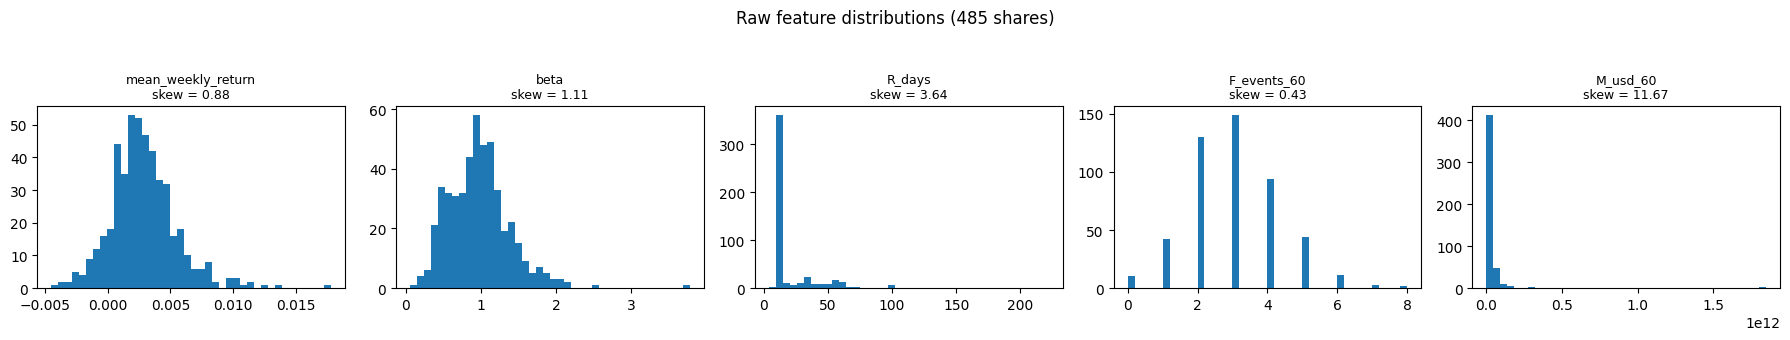

In [39]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, c in zip(axes, raw.columns):
    ax.hist(raw[c], bins=40)
    ax.set_title(f"{c}\nskew = {raw[c].skew():.2f}", fontsize=9)
plt.suptitle("Raw feature distributions (485 shares)", y=1.05)
plt.tight_layout()
plt.savefig("figures/2_1_raw_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.1.3 log1p transformation and standardisation

In [40]:
X_rfm = pd.DataFrame({
    "log1p_R":   np.log1p(X_rfm_raw["R_days"]),
    "F":         X_rfm_raw["F_events_60"],
    "log1p_M":   np.log1p(X_rfm_raw["M_usd_60"]),
}, index=common)
X_rr = X_rr_raw.copy()

print("Skew before → after transformation:")
print(pd.DataFrame({
    "before": [X_rfm_raw["R_days"].skew(), X_rfm_raw["F_events_60"].skew(), X_rfm_raw["M_usd_60"].skew()],
    "after":  [X_rfm["log1p_R"].skew(), X_rfm["F"].skew(), X_rfm["log1p_M"].skew()],
}, index=["R", "F", "M"]).round(2))

Skew before → after transformation:
   before  after
R    3.64   1.59
F    0.43   0.43
M   11.67   1.08


In [41]:
scaler_rr, scaler_rfm = StandardScaler(), StandardScaler()
Z_rr  = pd.DataFrame(scaler_rr.fit_transform(X_rr),   index=common, columns=X_rr.columns)
Z_rfm = pd.DataFrame(scaler_rfm.fit_transform(X_rfm), index=common, columns=X_rfm.columns)

check_z = pd.concat([Z_rr, Z_rfm], axis=1)
print("Means (should be 0):");               print(check_z.mean().round(3))
print("\nStandard deviations (should be 1):"); print(check_z.std(ddof=0).round(3))

Z_rr.to_csv("data/matrix_risk_return_standardised.csv")
Z_rfm.to_csv("data/matrix_rfm_standardised.csv")

Means (should be 0):
mean_weekly_return    0.0
beta                  0.0
log1p_R              -0.0
F                    -0.0
log1p_M              -0.0
dtype: float64

Standard deviations (should be 1):
mean_weekly_return    1.0
beta                  1.0
log1p_R               1.0
F                     1.0
log1p_M               1.0
dtype: float64


## 2.2 Agglomerative clustering

In [42]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score

L_rr  = linkage(Z_rr.values,  method="ward", metric="euclidean")
L_rfm = linkage(Z_rfm.values, method="ward", metric="euclidean")

### 2.2.1 Dendrogram – risk-return features

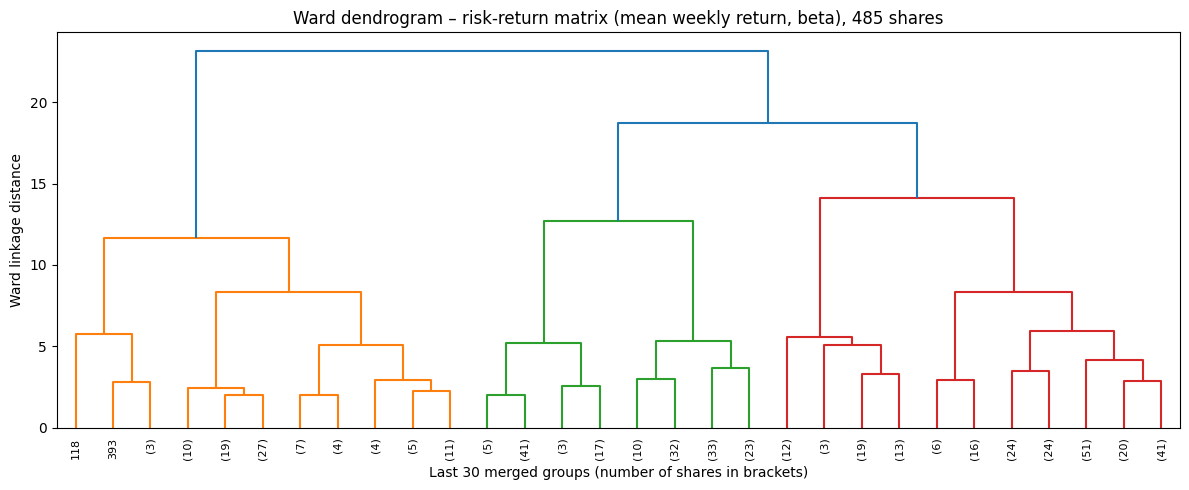

In [43]:
plt.figure(figsize=(12, 5))
dendrogram(L_rr, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8)
plt.title("Ward dendrogram – risk-return matrix (mean weekly return, beta), 485 shares")
plt.ylabel("Ward linkage distance")
plt.xlabel("Last 30 merged groups (number of shares in brackets)")
plt.tight_layout()
plt.savefig("figures/2_2_dendrogram_risk_return.png", dpi=150)
plt.show()

### 2.2.2 Dendrogram – RFM feature

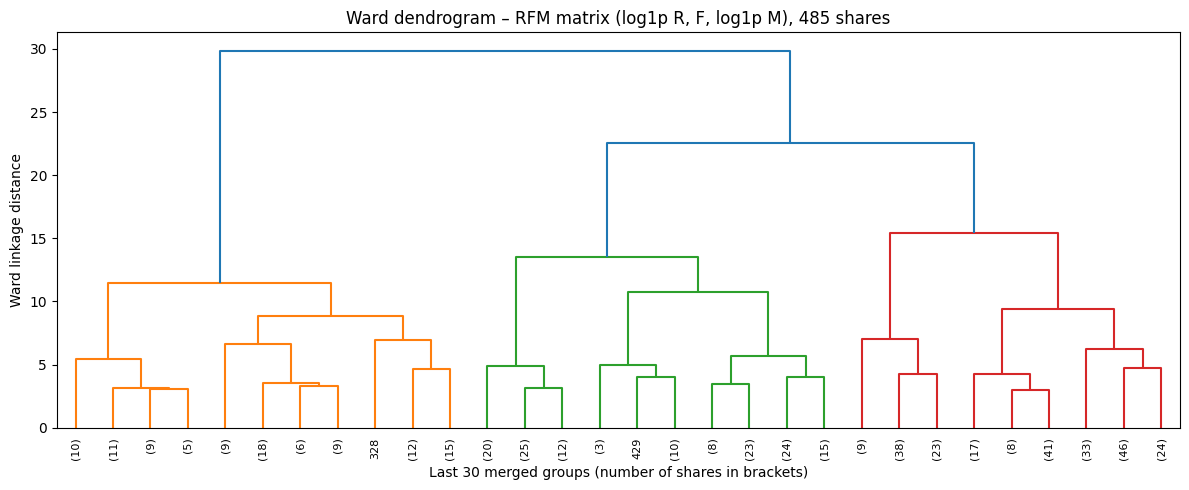

In [44]:
plt.figure(figsize=(12, 5))
dendrogram(L_rfm, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8)
plt.title("Ward dendrogram – RFM matrix (log1p R, F, log1p M), 485 shares")
plt.ylabel("Ward linkage distance")
plt.xlabel("Last 30 merged groups (number of shares in brackets)")
plt.tight_layout()
plt.savefig("figures/2_2_dendrogram_rfm.png", dpi=150)
plt.show()

### 2.2.3 Cluster count selection (k = 2 to 8)

In [45]:
def evaluate_ward(Z, L, name):
    rows = []
    for k in range(2, 9):
        labels = fcluster(L, k, criterion="maxclust")
        sizes = np.bincount(labels)[1:]
        rows.append({
            "matrix": name, "k": k,
            "silhouette": round(silhouette_score(Z, labels), 3),
            "merge height to k-1": round(L[-(k - 1), 2], 2),
            "smallest": int(sizes.min()), "largest": int(sizes.max()),
            "sizes": sorted(sizes.tolist(), reverse=True),
        })
    return pd.DataFrame(rows)

ward_eval = pd.concat([evaluate_ward(Z_rr, L_rr, "risk-return"),
                       evaluate_ward(Z_rfm, L_rfm, "RFM")], ignore_index=True)
ward_eval.to_csv("data/ward_k_selection.csv", index=False)
ward_eval

,matrix,k,silhouette,merge height to k-1,smallest,largest,sizes
0,risk-return,2,0.341,23.13,92,393,"[393, 92]"
1,risk-return,3,0.274,18.72,92,229,"[229, 164, 92]"
2,risk-return,4,0.282,14.11,47,182,"[182, 164, 92, 47]"
3,risk-return,5,0.304,12.71,47,182,"[182, 98, 92, 66, 47]"
4,risk-return,6,0.321,11.64,5,182,"[182, 98, 87, 66, 47, 5]"
5,risk-return,7,0.325,8.37,5,160,"[160, 98, 87, 66, 47, 22, 5]"
6,risk-return,8,0.323,8.33,5,160,"[160, 98, 66, 56, 47, 31, 22, 5]"
7,RFM,2,0.404,29.82,105,380,"[380, 105]"
8,RFM,3,0.336,22.57,105,239,"[239, 141, 105]"
9,RFM,4,0.294,15.43,70,169,"[169, 141, 105, 70]"


In [46]:
def ward_profiles(L, cols, k):
    df = features.loc[common, cols].copy()
    df["cluster"] = fcluster(L, k, criterion="maxclust")
    prof = df.groupby("cluster")[cols].median()
    prof.insert(0, "n shares", df["cluster"].value_counts().sort_index())
    return prof

rr_cols  = ["mean_weekly_return", "beta"]
rfm_cols = ["R_days", "F_events_60", "M_usd_60"]

for k in [2, 3, 4, 5]:
    print(f"\n=== Risk-return, Ward k={k} ===");  display(ward_profiles(L_rr, rr_cols, k).round(4))
for k in [2, 3, 4, 5]:
    print(f"\n=== RFM, Ward k={k} ===")
    p = ward_profiles(L_rfm, rfm_cols, k); p["M_usd_60"] = (p["M_usd_60"] / 1e9).round(1)
    display(p.rename(columns={"M_usd_60": "M ($bn)"}))


=== Risk-return, Ward k=2 ===


,n shares,mean_weekly_return,beta
cluster,,,
1,92,0.0055,1.2177
2,393,0.0021,0.8814



=== Risk-return, Ward k=3 ===


,n shares,mean_weekly_return,beta
cluster,,,
1,92,0.0055,1.2177
2,164,0.0033,0.5777
3,229,0.0017,1.0377



=== Risk-return, Ward k=4 ===


,n shares,mean_weekly_return,beta
cluster,,,
1,92,0.0055,1.2177
2,164,0.0033,0.5777
3,47,0.0025,1.5093
4,182,0.0017,0.9644


... (6 outputs left out)


=== RFM, Ward k=4 ===


,n shares,R_days,F_events_60,M ($bn)
cluster,,,,
1,105,47.0,2.0,19.6
2,141,11.0,3.0,42.0
3,70,11.0,4.0,13.8
4,169,11.0,3.0,9.3



=== RFM, Ward k=5 ===


,n shares,R_days,F_events_60,M ($bn)
cluster,,,,
1,105,47.0,2.0,19.6
2,57,11.0,2.0,32.4
3,84,11.0,4.0,49.3
4,70,11.0,4.0,13.8
5,169,11.0,3.0,9.3


In [47]:
K_WARD_RR, K_WARD_RFM = 5, 3

ward_rr_labels  = fcluster(L_rr,  K_WARD_RR,  criterion="maxclust")
ward_rfm_labels = fcluster(L_rfm, K_WARD_RFM, criterion="maxclust")

print(f"Ward risk-return k={K_WARD_RR}: silhouette {silhouette_score(Z_rr, ward_rr_labels):.3f}, sizes {np.bincount(ward_rr_labels)[1:].tolist()}")
print(f"Ward RFM k={K_WARD_RFM}:         silhouette {silhouette_score(Z_rfm, ward_rfm_labels):.3f}, sizes {np.bincount(ward_rfm_labels)[1:].tolist()}")

Ward risk-return k=5: silhouette 0.304, sizes [92, 66, 98, 47, 182]
Ward RFM k=3:         silhouette 0.336, sizes [105, 141, 239]


## 2.3 K-means clustering

In [48]:
from sklearn.cluster import KMeans
SEED = 42

def evaluate_kmeans(Z, name):
    rows = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
        sizes = np.bincount(km.labels_)
        rows.append({
            "matrix": name, "k": k,
            "silhouette": round(silhouette_score(Z, km.labels_), 3),
            "inertia": round(km.inertia_, 1),
            "smallest": int(sizes.min()), "largest": int(sizes.max()),
            "sizes": sorted(sizes.tolist(), reverse=True),
        })
    return pd.DataFrame(rows)

km_eval = pd.concat([evaluate_kmeans(Z_rr, "risk-return"),
                     evaluate_kmeans(Z_rfm, "RFM")], ignore_index=True)
km_eval.to_csv("data/kmeans_k_selection.csv", index=False)
km_eval

,matrix,k,silhouette,inertia,smallest,largest,sizes
0,risk-return,2,0.389,617.0,143,342,"[342, 143]"
1,risk-return,3,0.328,459.8,120,201,"[201, 164, 120]"
2,risk-return,4,0.326,370.2,41,162,"[162, 148, 134, 41]"
3,risk-return,5,0.340,308.2,29,166,"[166, 131, 109, 50, 29]"
4,risk-return,6,0.337,263.4,5,156,"[156, 127, 106, 51, 40, 5]"
5,risk-return,7,0.335,225.1,5,144,"[144, 81, 72, 71, 62, 50, 5]"
6,risk-return,8,0.361,192.7,5,139,"[139, 76, 75, 74, 47, 40, 29, 5]"
7,RFM,2,0.416,996.1,102,383,"[383, 102]"
8,RFM,3,0.343,739.8,90,256,"[256, 139, 90]"
9,RFM,4,0.361,557.8,83,194,"[194, 119, 89, 83]"


### 2.3.1 / 2.3.2 Cluster count selection – elbow and silhouette

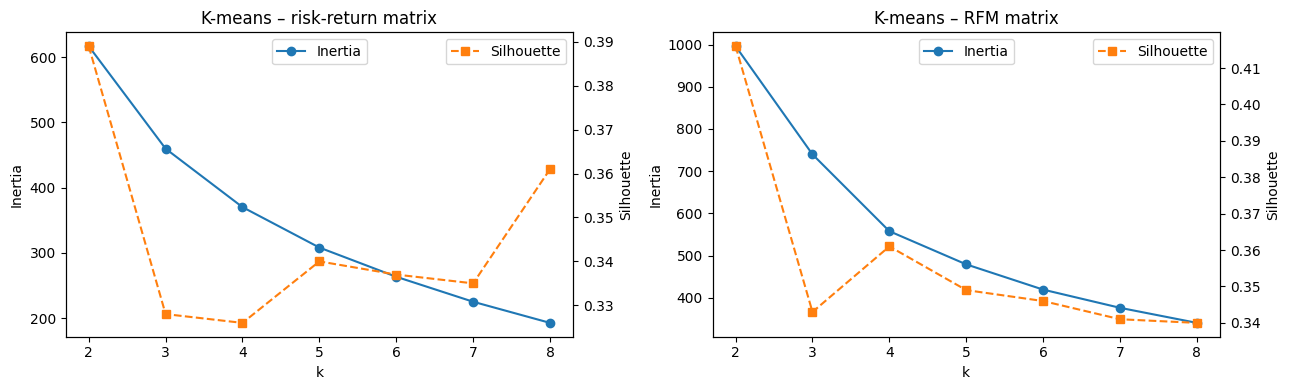

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, ["risk-return", "RFM"]):
    d = km_eval[km_eval["matrix"] == name]
    ax.plot(d["k"], d["inertia"], marker="o", label="Inertia")
    ax.set_xlabel("k"); ax.set_ylabel("Inertia"); ax.set_title(f"K-means – {name} matrix")
    ax2 = ax.twinx()
    ax2.plot(d["k"], d["silhouette"], marker="s", linestyle="--", color="tab:orange", label="Silhouette")
    ax2.set_ylabel("Silhouette")
    ax.legend(loc="upper center"); ax2.legend(loc="upper right")
plt.tight_layout()
plt.savefig("figures/2_3_kmeans_elbow_silhouette.png", dpi=150)
plt.show()

In [50]:
def km_profiles(Z, cols, k):
    labels = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(Z)
    df = features.loc[common, cols].copy(); df["cluster"] = labels
    prof = df.groupby("cluster")[cols].median()
    prof.insert(0, "n shares", df["cluster"].value_counts().sort_index())
    return prof

for k in [3, 4, 5, 6]:
    print(f"\n=== Risk-return, K-means k={k} ==="); display(km_profiles(Z_rr, rr_cols, k).round(4))
for k in [2, 3, 4]:
    print(f"\n=== RFM, K-means k={k} ===")
    p = km_profiles(Z_rfm, rfm_cols, k); p["M_usd_60"] = (p["M_usd_60"] / 1e9).round(1)
    display(p.rename(columns={"M_usd_60": "M ($bn)"}))


=== Risk-return, K-means k=3 ===


,n shares,mean_weekly_return,beta
cluster,,,
0,201,0.0026,0.6210
1,164,0.0012,1.0728
2,120,0.0052,1.2244



=== Risk-return, K-means k=4 ===


,n shares,mean_weekly_return,beta
cluster,,,
0,41,0.0069,1.6772
1,134,0.0012,1.1394
2,162,0.0043,0.9674
3,148,0.0018,0.5674



=== Risk-return, K-means k=5 ===


,n shares,mean_weekly_return,beta
cluster,,,
0,109,0.0008,1.0358
1,166,0.0042,0.9851
2,131,0.0019,0.5342
3,29,0.0081,1.4468
4,50,0.0027,1.5254


... (4 outputs left out)


=== RFM, K-means k=3 ===


,n shares,R_days,F_events_60,M ($bn)
cluster,,,,
0,139,11.0,3.0,42.9
1,256,11.0,3.0,11.2
2,90,53.5,2.0,21.2



=== RFM, K-means k=4 ===


,n shares,R_days,F_events_60,M ($bn)
cluster,,,,
0,194,11.0,2.0,13.1
1,89,54.0,2.0,21.2
2,83,11.0,3.0,63.2
3,119,11.0,4.0,12.7


### 2.3.3 Final K-means models

In [51]:
K_KM_RR, K_KM_RFM = 5, 3

km_rr  = KMeans(n_clusters=K_KM_RR,  n_init=50, random_state=SEED).fit(Z_rr)
km_rfm = KMeans(n_clusters=K_KM_RFM, n_init=50, random_state=SEED).fit(Z_rfm)
km_rr_labels, km_rfm_labels = km_rr.labels_ + 1, km_rfm.labels_ + 1

print(f"K-means risk-return k={K_KM_RR}: silhouette {silhouette_score(Z_rr, km_rr_labels):.3f}, sizes {np.bincount(km_rr_labels)[1:].tolist()}")
print(f"K-means RFM k={K_KM_RFM}:         silhouette {silhouette_score(Z_rfm, km_rfm_labels):.3f}, sizes {np.bincount(km_rfm_labels)[1:].tolist()}")

K-means risk-return k=5: silhouette 0.340, sizes [109, 166, 131, 29, 50]
K-means RFM k=3:         silhouette 0.343, sizes [139, 256, 90]


In [52]:
from sklearn.metrics import adjusted_rand_score

seeds = [0, 1, 7, 21, 99, 123, 2024, 31415]
stability = []
for name, Z, k, ref in [("risk-return", Z_rr, K_KM_RR, km_rr_labels), ("RFM", Z_rfm, K_KM_RFM, km_rfm_labels)]:
    aris = [adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=50, random_state=s).fit_predict(Z)) for s in seeds]
    stability.append({"matrix": name, "k": k, "seeds tested": len(seeds),
                      "min ARI vs seed 42": round(min(aris), 3), "mean ARI vs seed 42": round(np.mean(aris), 3)})
stability = pd.DataFrame(stability)
stability.to_csv("data/kmeans_seed_stability.csv", index=False)
stability

,matrix,k,seeds tested,min ARI vs seed 42,mean ARI vs seed 42
0,risk-return,5,8,0.928,0.958
1,RFM,3,8,1.000,1.000


## 2.4 Cluster profiles and algorithm comparison

### 2.4.1 Cluster profiles in original units

In [53]:
assign = features.loc[common, ["sector", "mean_weekly_return", "beta", "R_days", "F_events_60", "M_usd_60"]].copy()
assign["ward_rr"], assign["kmeans_rr"]   = ward_rr_labels, km_rr_labels
assign["ward_rfm"], assign["kmeans_rfm"] = ward_rfm_labels, km_rfm_labels
assign.to_csv("data/cluster_assignments.csv")

def profile_table(label_col, cols):
    g = assign.groupby(label_col)
    prof = g[cols].median()
    prof.insert(0, "n shares", g.size())
    if "mean_weekly_return" in prof: prof["mean_weekly_return"] = (prof["mean_weekly_return"] * 100).round(2)
    if "M_usd_60" in prof: prof["M_usd_60"] = (prof["M_usd_60"] / 1e9).round(1)
    return prof.rename(columns={"mean_weekly_return": "median weekly return (%)", "beta": "median beta",
                                "R_days": "median R (days)", "F_events_60": "median F", "M_usd_60": "median M ($bn)"})

for col, cols, title in [("ward_rr", rr_cols, "Ward – risk-return"), ("kmeans_rr", rr_cols, "K-means – risk-return"),
                         ("ward_rfm", rfm_cols, "Ward – RFM"), ("kmeans_rfm", rfm_cols, "K-means – RFM")]:
    print(f"\n=== {title} ===")
    p = profile_table(col, cols); p.to_csv(f"data/profile_{col}.csv"); display(p.round(3))


=== Ward – risk-return ===


,n shares,median weekly return (%),median beta
ward_rr,,,
1,92,0.55,1.218
2,66,0.11,0.449
3,98,0.39,0.666
4,47,0.25,1.509
5,182,0.17,0.964



=== K-means – risk-return ===


,n shares,median weekly return (%),median beta
kmeans_rr,,,
1,109,0.08,1.036
2,166,0.42,0.985
3,131,0.19,0.534
4,29,0.81,1.447
5,50,0.27,1.525



=== Ward – RFM ===


,n shares,median R (days),median F,median M ($bn)
ward_rfm,,,,
1,105,47.0,2.0,19.6
2,141,11.0,3.0,42.0
3,239,11.0,3.0,11.2



=== K-means – RFM ===


,n shares,median R (days),median F,median M ($bn)
kmeans_rfm,,,,
1,139,11.0,3.0,42.9
2,256,11.0,3.0,11.2
3,90,53.5,2.0,21.2


### 2.4.2 Two-dimensional visualisations

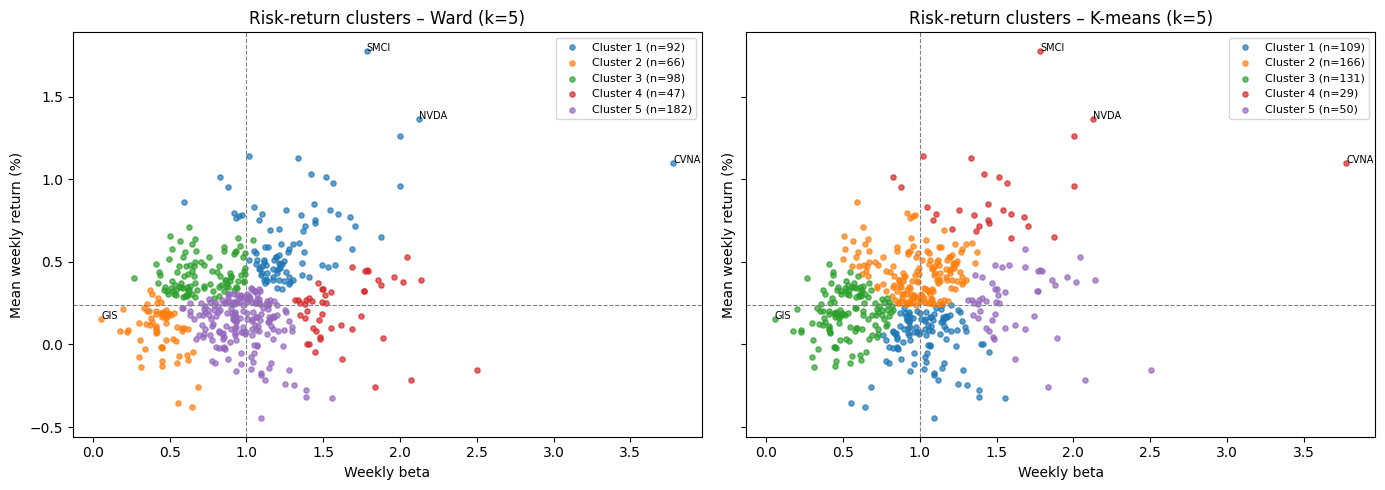

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, col, title in [(axes[0], "ward_rr", f"Ward (k={K_WARD_RR})"), (axes[1], "kmeans_rr", f"K-means (k={K_KM_RR})")]:
    for c in sorted(assign[col].unique()):
        d = assign[assign[col] == c]
        ax.scatter(d["beta"], d["mean_weekly_return"] * 100, s=14, alpha=0.7, label=f"Cluster {c} (n={len(d)})")
    ax.axhline(bench_ret.mean() * 100, color="grey", lw=0.8, ls="--")
    ax.axvline(1, color="grey", lw=0.8, ls="--")
    ax.set_title(f"Risk-return clusters – {title}")
    ax.set_xlabel("Weekly beta"); ax.set_ylabel("Mean weekly return (%)"); ax.legend(fontsize=8)
for t in ["CVNA", "NVDA", "SMCI", "GIS"]:
    for ax in axes:
        ax.annotate(t, (assign.at[t, "beta"], assign.at[t, "mean_weekly_return"] * 100), fontsize=7)
plt.tight_layout()
plt.savefig("figures/2_4_risk_return_clusters.png", dpi=150)
plt.show()

Variance explained by PC1, PC2: [0.437 0.337] | total: 0.774

Loadings (how each feature contributes to each component):


,PC1,PC2
log1p_R,0.712,0.029
F,-0.650,0.403
log1p_M,0.263,0.915


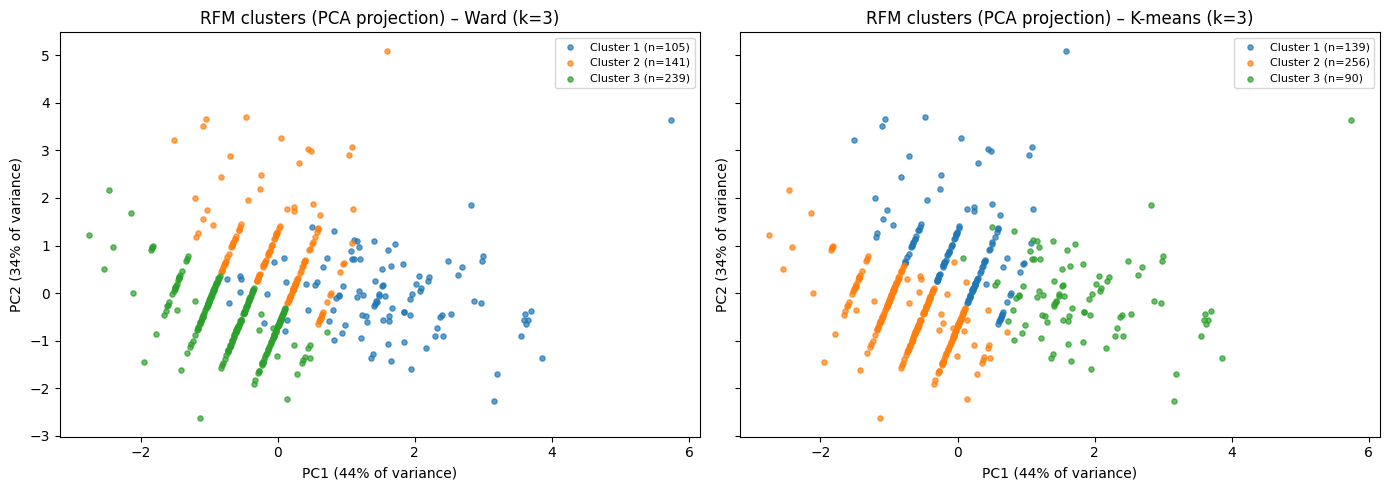

In [55]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=SEED).fit(Z_rfm)
P = pca.transform(Z_rfm)
print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", round(pca.explained_variance_ratio_.sum(), 3))
print("\nLoadings (how each feature contributes to each component):")
display(pd.DataFrame(pca.components_.T, index=Z_rfm.columns, columns=["PC1", "PC2"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, col, title in [(axes[0], "ward_rfm", f"Ward (k={K_WARD_RFM})"), (axes[1], "kmeans_rfm", f"K-means (k={K_KM_RFM})")]:
    for c in sorted(assign[col].unique()):
        m = (assign[col] == c).values
        ax.scatter(P[m, 0], P[m, 1], s=14, alpha=0.7, label=f"Cluster {c} (n={m.sum()})")
    ax.set_title(f"RFM clusters (PCA projection) – {title}")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/2_4_rfm_clusters_pca.png", dpi=150)
plt.show()

### 2.4.3 Ward vs K-means comparison

In [56]:
from sklearn.metrics import adjusted_rand_score

comparison = pd.DataFrame({
    "Ward silhouette":    [silhouette_score(Z_rr, ward_rr_labels), silhouette_score(Z_rfm, ward_rfm_labels)],
    "K-means silhouette": [silhouette_score(Z_rr, km_rr_labels),   silhouette_score(Z_rfm, km_rfm_labels)],
    "Adjusted Rand index (Ward vs K-means)": [adjusted_rand_score(ward_rr_labels, km_rr_labels),
                                              adjusted_rand_score(ward_rfm_labels, km_rfm_labels)],
}, index=["Risk-return (k=5)", "RFM (k=3)"]).round(3)
comparison.to_csv("data/algorithm_comparison.csv")
display(comparison)

print("Risk-return – how Ward clusters map to K-means clusters:")
display(pd.crosstab(assign["ward_rr"], assign["kmeans_rr"], rownames=["Ward"], colnames=["K-means"]))
print("RFM – how Ward clusters map to K-means clusters:")
display(pd.crosstab(assign["ward_rfm"], assign["kmeans_rfm"], rownames=["Ward"], colnames=["K-means"]))

,Ward silhouette,K-means silhouette,Adjusted Rand index (Ward vs K-means)
Risk-return (k=5),0.304,0.340,0.320
RFM (k=3),0.336,0.343,0.881


Risk-return – how Ward clusters map to K-means clusters:


K-means,1,2,3,4,5
Ward,,,,,
1,0,57,0,29,6
2,3,0,63,0,0
3,0,62,36,0,0
4,3,0,0,0,44
5,103,47,32,0,0


RFM – how Ward clusters map to K-means clusters:


K-means,1,2,3
Ward,,,
1,3,12,90
2,136,5,0
3,0,239,0


## 2.5 RFM sensitivity and correlated inputs

### 2.5.1 Correlation analysis (R, F, log1p(M))

In [57]:
corr_pearson  = X_rfm.corr(method="pearson").round(3)
corr_spearman = X_rfm.corr(method="spearman").round(3)
corr_pearson.to_csv("data/rfm_correlations_pearson.csv")
corr_spearman.to_csv("data/rfm_correlations_spearman.csv")

print("Pearson correlations (log1p R, F, log1p M):");   display(corr_pearson)
print("Spearman (rank) correlations:");     display(corr_spearman)

Pearson correlations (log1p R, F, log1p M):


,log1p_R,F,log1p_M
log1p_R,1.000,-0.289,0.127
F,-0.289,1.000,0.014
log1p_M,0.127,0.014,1.000


Spearman (rank) correlations:


,log1p_R,F,log1p_M
log1p_R,1.000,-0.201,0.138
F,-0.201,1.000,-0.047
log1p_M,0.138,-0.047,1.000


### 2.5.2 Removal of Monetary (R and F only)

In [58]:
X_rf  = X_rfm[["log1p_R", "F"]]
Z_rf  = pd.DataFrame(StandardScaler().fit_transform(X_rf), index=common, columns=X_rf.columns)
L_rf  = linkage(Z_rf.values, method="ward", metric="euclidean")
ward_rf_labels = fcluster(L_rf, K_WARD_RFM, criterion="maxclust")
assign["ward_rf_noM"] = ward_rf_labels
assign.to_csv("data/cluster_assignments.csv")

ari_noM = adjusted_rand_score(ward_rfm_labels, ward_rf_labels)
print(f"Ward R+F only (k={K_WARD_RFM}): silhouette {silhouette_score(Z_rf, ward_rf_labels):.3f}, "
      f"sizes {np.bincount(ward_rf_labels)[1:].tolist()}")
print(f"Adjusted Rand index vs full RFM Ward solution: {ari_noM:.3f}")

print("\nMembership comparison:")
display(pd.crosstab(assign["ward_rfm"], assign["ward_rf_noM"],
                    rownames=["Ward R+F+M"], colnames=["Ward R+F only"]))

Ward R+F only (k=3): silhouette 0.510, sizes [108, 125, 252]
Adjusted Rand index vs full RFM Ward solution: 0.347

Membership comparison:


Ward R+F only,1,2,3
Ward R+F+M,,,
1,100,0,5
2,8,59,74
3,0,66,173


In [59]:
def m_profile(col):
    g = assign.groupby(col)["M_usd_60"]
    return pd.DataFrame({
        "n shares":        g.size(),
        "median R":        assign.groupby(col)["R_days"].median(),
        "median F":        assign.groupby(col)["F_events_60"].median(),
        "M 25th pct ($bn)": (g.quantile(0.25) / 1e9).round(1),
        "M median ($bn)":   (g.median() / 1e9).round(1),
        "M 75th pct ($bn)": (g.quantile(0.75) / 1e9).round(1),
    })

print("With Monetary (R + F + M):");   p1 = m_profile("ward_rfm");    display(p1)
print("Without Monetary (R + F only):"); p2 = m_profile("ward_rf_noM"); display(p2)
p1.to_csv("data/profile_ward_rfm_traded_value.csv"); p2.to_csv("data/profile_ward_rf_noM_traded_value.csv")

With Monetary (R + F + M):


,n shares,median R,median F,M 25th pct ($bn),M median ($bn),M 75th pct ($bn)
ward_rfm,,,,,,
1,105,47.0,2.0,13.4,19.6,32.7
2,141,11.0,3.0,28.4,42.0,69.9
3,239,11.0,3.0,7.8,11.2,14.8


Without Monetary (R + F only):


,n shares,median R,median F,M 25th pct ($bn),M median ($bn),M 75th pct ($bn)
ward_rf_noM,,,,,,
1,108,46.5,2.0,13.4,21.0,38.4
2,125,11.0,2.0,10.5,17.7,31.8
3,252,11.0,4.0,9.3,14.7,28.3


# Task 3 – Business Intelligence Outputs

## 3.2.1 Sector composition of clusters

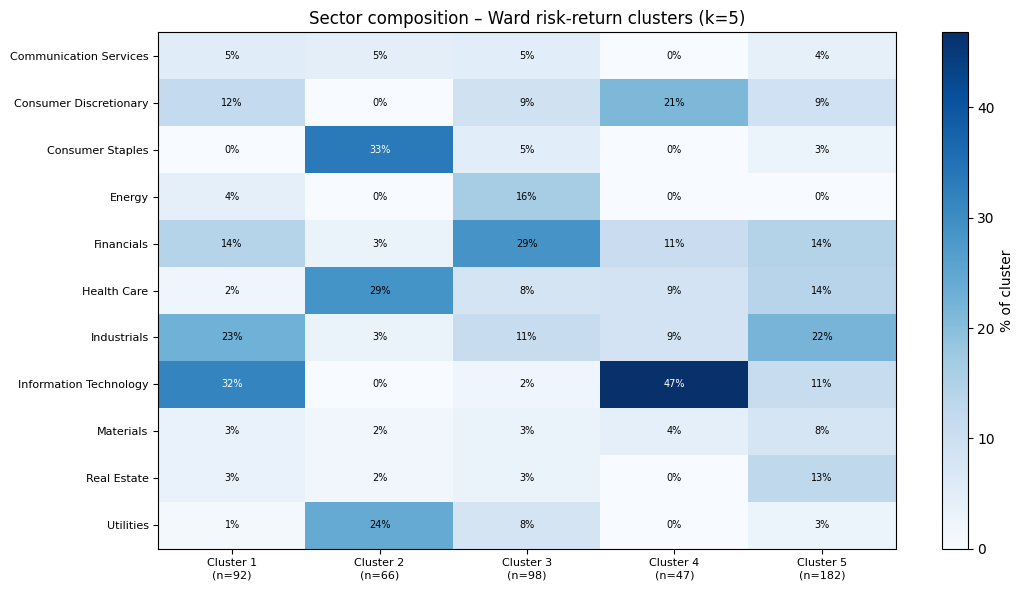

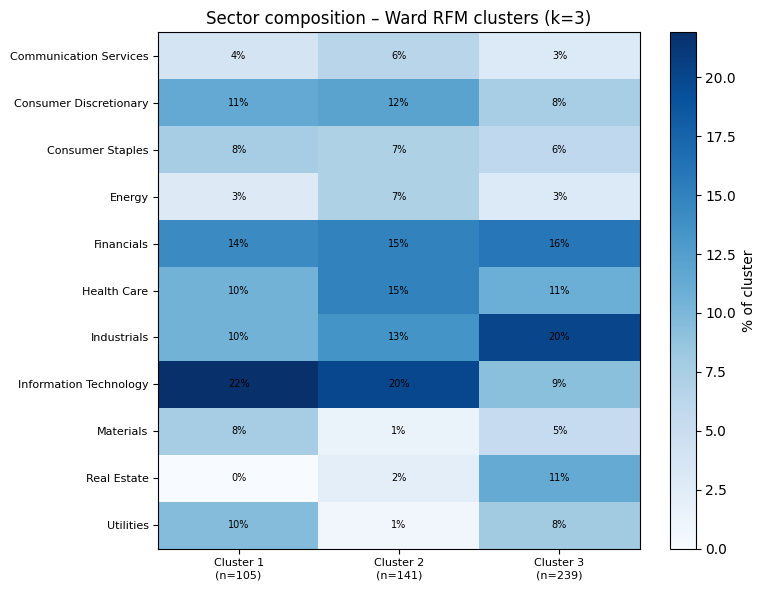

,Cluster 1\n(n=105),Cluster 2\n(n=141),Cluster 3\n(n=239)
sector,,,
Communication Services,3.8,6.4,2.9
Consumer Discretionary,11.4,12.1,7.5
Consumer Staples,7.6,7.1,5.9
Energy,2.9,7.1,2.9
Financials,14.3,14.9,15.9
Health Care,10.5,14.9,10.9
Industrials,10.5,13.5,20.1
Information Technology,21.9,19.9,9.2
Materials,7.6,1.4,5.4


In [61]:
def sector_mix(col, title, fname):
    tab = pd.crosstab(assign["sector"], assign[col], normalize="columns") * 100
    tab.columns = [f"Cluster {c}\n(n={(assign[col] == c).sum()})" for c in tab.columns]
    tab.round(1).to_csv(f"data/sector_mix_{col}.csv")
    fig, ax = plt.subplots(figsize=(1.6 * tab.shape[1] + 3, 6))
    im = ax.imshow(tab.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns, fontsize=8)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index, fontsize=8)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=7, color="white" if v > 30 else "black")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label="% of cluster")
    plt.tight_layout(); plt.savefig(f"figures/{fname}.png", dpi=150); plt.show()
    return tab.round(1)

sector_mix("ward_rr",  "Sector composition – Ward risk-return clusters (k=5)", "3_2_sector_mix_risk_return")
sector_mix("ward_rfm", "Sector composition – Ward RFM clusters (k=3)",         "3_2_sector_mix_rfm")